# Lab 01 — Skin Lesion Classification (ISIC, 9 classes)

Transfer learning on the [Skin Cancer ISIC 9-class dataset](https://www.kaggle.com/datasets/nodoubttome/skin-cancer9-classesisic),
producing the three tables from **Task 01.docx**:

| | Table | What it compares |
|---|---|---|
| 1️⃣ | **Table 1** — Transfer Learning Models | 8 ImageNet CNNs × Accuracy / Precision / Recall / F1 / AUC |
| 2️⃣ | **Table 3** — Computational Efficiency | 7 CNNs × Params / Size / FLOPs / Latency / Accuracy |
| 3️⃣ | **Table 2** — Different Classifiers | 8 deep-feature extractors × 7 classical classifiers |

> Cells run in the order **Table 1 → Table 3 → Table 2**. That is also the dependency
> order: Table 3 reuses Table 1's accuracy column, and Table 2 reuses the deep features
> already cached during Table 1.

### Experimental protocol
- **Split** — the official `Train/` folder is split **80/20 stratified** into train/val.
  The official `Test/` folder is the held-out set every reported metric uses.
- **Transfer learning** — backbones are **frozen** ImageNet feature extractors; only a
  linear classifier head is trained. Loss is class-weighted (the ISIC classes are
  heavily imbalanced) and the best epoch is selected on validation macro-F1.
- **Metrics** — Precision / Recall / F1 are **macro-averaged**; AUC is **macro one-vs-rest**.

### Why this is fast
Freezing the backbone means each image can be **decoded once into a RAM cache**, and each
backbone runs **exactly one forward pass** over that cache. Those cached features then feed
*both* the Table 1 linear head and the whole Table 2 classifier grid — so the 56-cell grid
costs almost nothing extra.

On top of that: checkpoints download 4-at-a-time, the linear head trains for **10 epochs**
(no weight decay, higher LR to compensate), Table 2 classifiers are reduced to 128 PCA
components, and **Table 3 builds its models with random init** — parameter count, model
size, FLOPs and latency depend only on the architecture, never on the weight values, so
this skips re-reading 1.7 GB from disk and changes none of the measured numbers.

**Trade-off:** no per-epoch augmentation, and accuracy sits below what a full fine-tune
would reach. Set `fine_tune=True` in the config cell to unfreeze the backbones instead.

---

### ⚠️ Running on Colab **free tier**

This notebook is tuned for the free runtime (T4, ~12.7 GB RAM, 2 vCPUs):

| Constraint | How it's handled |
|---|---|
| **GPU required** | *Runtime → Change runtime type → **T4 GPU***. On CPU this takes hours — the runtime check below will tell you and print a reduced config. |
| **~12.7 GB RAM** | The pixel cache is ~250 MB and the deep-feature cache ~130 MB. Backbones are freed between models. |
| **~1.7 GB of weights** | Fetched **4 in parallel** by `prefetch_weights` instead of one at a time (VGG16/VGG19 are ~0.5 GB each), then cached for the session. Still the largest single cost. |
| **Disconnects** | Every table is written to `results/*.csv` **as each row completes**, so a dropped session costs at most one model. |
| **90-min idle timeout** | The full run is ~8–12 min, well inside it. Keep the tab active. |

**If you run out of GPU quota**, the runtime check prints a smaller model list that is
tractable on CPU.

---
**To run:** set the T4 GPU runtime, then *Runtime → Run all*.

## 0 · Environment setup

In [ ]:
# Colab already ships torch, torchvision, scikit-learn, xgboost, pandas and matplotlib.
# Only these two are missing on a stock free-tier runtime.
!pip install -q kagglehub python-docx

import sys, importlib, torch, torchvision
print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
for mod in ("sklearn", "xgboost", "pandas", "matplotlib", "kagglehub", "docx", "psutil"):
    try:
        m = importlib.import_module(mod)
        print("%-12s: %s" % (mod, getattr(m, "__version__", "ok")))
    except ImportError:
        print("%-12s: MISSING" % mod)

print("\nCUDA        :", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
if not torch.cuda.is_available():
    print("\n*** No GPU detected. Runtime -> Change runtime type -> T4 GPU, "
          "otherwise this notebook will take hours. ***")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 10.3 MB/s eta 0:00:00
python      : 3.13.15
torch       : 2.11.0+cu128
torchvision : 0.26.0+cu128
sklearn     : 1.6.1
xgboost     : 3.4.1
pandas      : 2.2.3
matplotlib  : 3.10.0
kagglehub   : 1.0.2
docx        : 1.2.0
psutil      : 5.9.5

CUDA        : True | Tesla T4


## 1 · The pipeline module

The next cell writes **`task.py`** — the single source of truth for the whole lab. The rest
of the notebook just calls into it, so the notebook and the standalone script can never
drift apart. You can also run it head-less with `!python task.py`.

In [ ]:
%%writefile task.py
"""
Lab 01 - Skin Lesion Classification on the ISIC 9-class dataset
================================================================
Reproduces the three tables in "Task 01.docx":

  Table 1  Comparison of Transfer Learning Models      (8 CNNs x 5 metrics)
  Table 3  Computational Efficiency Comparison         (7 CNNs x 5 columns)
  Table 2  Comparison of Different Classifiers         (8 extractors x 7 classifiers)

Run order is Table 1 -> Table 3 -> Table 2 (Table 3 reuses Table 1 accuracies,
Table 2 reuses the cached deep features computed for Table 1).

Dataset : https://www.kaggle.com/datasets/nodoubttome/skin-cancer9-classesisic
Protocol: the official Train/ folder is split 80/20 (stratified) into train/val;
          the official Test/ folder is the held-out set all reported metrics use.

Transfer-learning strategy
--------------------------
Backbones are FROZEN ImageNet feature extractors; only a linear classifier head is
trained. That keeps the whole study inside a ~10 minute Colab T4 budget, because
each image is decoded once into a RAM cache and each backbone runs exactly ONE
forward pass over the data. Those cached features then serve both Table 1 (linear
head) and Table 2 (classical classifiers), so the 56-cell grid is nearly free.

Set Config.fine_tune = True to unfreeze the backbones instead (far slower, higher
accuracy).

Usage
-----
    python task.py                # full run, writes ./results/
    python task.py --quick        # tiny smoke test
    python task.py --fine-tune    # unfreeze backbones
"""

from __future__ import annotations

import argparse
import json
import os
import random
import time
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from PIL import Image

warnings.filterwarnings("ignore")


# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
@dataclass
class Config:
    # data
    img_size: int = 224
    val_fraction: float = 0.20                # carved out of the official Train/ folder
    max_train_per_class: int | None = 150     # subsample cap -> ~10 min runtime; None = use all
    seed: int = 42

    # feature extraction
    batch_size: int = 96          # larger batch = better T4 utilisation
    decode_workers: int = 8       # free Colab has ~2 vCPUs; decode is I/O bound

    # Table 1 linear head (trained on cached features, so this is nearly free).
    # At 10 epochs the batch size matters more than the epoch count: batch 64 over
    # ~1085 training rows gives ~17 steps/epoch, so 10 epochs is ~170 optimiser
    # steps - enough for a linear layer on standardised features. The higher LR
    # (3e-3, cosine-decayed) compensates for the short schedule.
    head_epochs: int = 10
    head_lr: float = 3e-3
    head_weight_decay: float = 0.0    # no weight decay; best epoch is picked on val macro-F1
    head_batch_size: int = 64

    # optional full fine-tuning (off by default - see module docstring)
    fine_tune: bool = False
    ft_epochs: int = 8
    ft_lr: float = 1e-4

    # Table 2 classical classifiers. These are the dominant CPU cost on a 2-vCPU
    # free runtime (56 fits), so they are sized for speed rather than the last 0.5%.
    pca_dim: int = 128                        # after standardisation; 128 keeps ~all the signal
    rf_trees: int = 150
    xgb_estimators: int = 100
    xgb_max_depth: int = 5
    svm_max_iter: int = 2000

    # Table 3. Params / size / FLOPs / latency depend only on the ARCHITECTURE, never
    # on the weight values, so these models are built with random init - that skips
    # re-reading ~1.7 GB of checkpoints from disk and changes no measured number.
    table3_pretrained: bool = False
    latency_warmup: int = 8
    latency_runs: int = 20

    out_dir: str = "results"

    # Table 1 / Table 2 model list (Table 3 omits ResNet101, per the docx)
    models: tuple = (
        "AlexNet", "VGG16", "VGG19", "ResNet18",
        "ResNet50", "ResNet101", "DenseNet121", "EfficientNet-B0",
    )
    efficiency_models: tuple = (
        "AlexNet", "VGG16", "VGG19", "ResNet18",
        "ResNet50", "DenseNet121", "EfficientNet-B0",
    )


CLASSIFIER_ORDER = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "K-Nearest Neighbors (KNN)",
    "Linear SVM",
    "RBF-SVM",
    "XGBoost",
]

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def banner(text: str) -> None:
    print("\n" + "=" * 78)
    print(text)
    print("=" * 78)


# Approximate ImageNet checkpoint sizes (MB), for the download estimate.
WEIGHT_MB = {
    "AlexNet": 233, "VGG16": 528, "VGG19": 548, "ResNet18": 45,
    "ResNet50": 98, "ResNet101": 171, "DenseNet121": 31, "EfficientNet-B0": 21,
}


def runtime_check(cfg, verbose=True):
    """Report what this Colab runtime can deliver and flag free-tier problems.

    Warns only - it never silently shrinks the experiment. If there is no GPU it
    prints the exact config change that makes the run tractable on CPU.
    """
    import shutil

    device = get_device()
    lines = []

    if device.type == "cuda":
        props = torch.cuda.get_device_properties(0)
        lines.append("GPU        : %s (%.1f GB VRAM)" % (props.name, props.total_memory / 1024 ** 3))
    else:
        lines.append("GPU        : NONE - running on CPU")

    try:
        import psutil

        vm = psutil.virtual_memory()
        lines.append("System RAM : %.1f GB total, %.1f GB available"
                     % (vm.total / 1024 ** 3, vm.available / 1024 ** 3))
    except Exception:
        pass

    try:
        du = shutil.disk_usage(".")
        lines.append("Disk       : %.1f GB free" % (du.free / 1024 ** 3))
    except Exception:
        pass

    dl_mb = sum(WEIGHT_MB.get(m, 100) for m in cfg.models)
    lines.append("Weights    : ~%.1f GB of ImageNet checkpoints on first run "
                 "(cached afterwards)" % (dl_mb / 1024))

    # Rough RAM footprint of the decode cache.
    px = cfg.img_size ** 2 * 3
    approx_imgs = (cfg.max_train_per_class or 250) * 9 + 448 + 118
    lines.append("Pixel cache: ~%.0f MB RAM" % (approx_imgs * px / 1024 ** 2))

    if verbose:
        banner("RUNTIME CHECK")
        for line in lines:
            print(" ", line)

        if device.type == "cuda":
            print("\n  Estimated wall time: ~8-12 min for all three tables "
                  "(most of it the one-off weight download).")
        else:
            print("\n  *** No GPU. The full study would take HOURS on 2 free-tier vCPUs. ***")
            print("  Either:  Runtime -> Change runtime type -> T4 GPU   (recommended)")
            print("  Or run a reduced study by editing the config cell to:")
            print("      cfg.max_train_per_class = 40")
            print("      cfg.head_epochs = 30")
            print("      cfg.models = ('AlexNet','ResNet18','DenseNet121','EfficientNet-B0')")
            print("      cfg.efficiency_models = cfg.models")
    return device


def checkpoint_table(df, filename, out_dir, verbose=False):
    """Persist partial results as they land, so a Colab disconnect costs at most one row."""
    try:
        out = Path(out_dir)
        out.mkdir(parents=True, exist_ok=True)
        df.to_csv(out / filename, index=False)
        if verbose:
            print("  [checkpoint] %s" % (out / filename))
    except Exception as exc:
        print("  [warn] could not checkpoint %s: %s" % (filename, exc))


def free_memory(device):
    """Release CPU and GPU memory between backbones - matters on a 12 GB free runtime."""
    import gc

    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


# ----------------------------------------------------------------------------
# Dataset discovery
# ----------------------------------------------------------------------------
def download_dataset() -> str:
    """Pull the Kaggle dataset via kagglehub and return the local root path."""
    import kagglehub

    path = kagglehub.dataset_download("nodoubttome/skin-cancer9-classesisic")
    print("Path to dataset files:", path)
    return path


def _iter_dirs(root: Path, max_depth: int = 4):
    """Directory-only BFS, so we never stat the thousands of image files."""
    stack = [(Path(root), 0)]
    while stack:
        d, depth = stack.pop()
        yield d
        if depth >= max_depth:
            continue
        try:
            for entry in os.scandir(d):
                if entry.is_dir():
                    stack.append((Path(entry.path), depth + 1))
        except OSError:
            pass


def _has_class_subdirs(d: Path) -> bool:
    """True if d looks like a split folder: >=2 subfolders, at least one holding images."""
    subdirs = [s for s in d.iterdir() if s.is_dir()]
    if len(subdirs) < 2:
        return False
    for s in subdirs:
        for f in s.iterdir():
            if f.suffix.lower() in IMG_EXTENSIONS:
                return True
    return False


def find_split_dirs(root):
    """Locate the Train/ and Test/ folders wherever Kaggle happened to nest them."""
    train_dir = test_dir = None
    for d in _iter_dirs(Path(root)):
        name = d.name.lower()
        try:
            if train_dir is None and name in ("train", "training") and _has_class_subdirs(d):
                train_dir = d
            elif test_dir is None and name in ("test", "testing") and _has_class_subdirs(d):
                test_dir = d
        except OSError:
            continue
        if train_dir is not None and test_dir is not None:
            break
    if train_dir is None or test_dir is None:
        raise FileNotFoundError(
            "Could not locate Train/ and Test/ under %s (train=%s, test=%s)"
            % (root, train_dir, test_dir)
        )
    return train_dir, test_dir


def list_split(split_dir: Path, classes=None):
    """Return (classes, [(filepath, label), ...]) for one split folder."""
    if classes is None:
        classes = sorted(d.name for d in split_dir.iterdir() if d.is_dir())
    items = []
    for idx, cname in enumerate(classes):
        cdir = split_dir / cname
        if not cdir.is_dir():
            continue
        for f in sorted(cdir.iterdir()):
            if f.suffix.lower() in IMG_EXTENSIONS:
                items.append((str(f), idx))
    return classes, items


def stratified_split(items, val_fraction, seed):
    """Split (path, label) pairs while preserving per-class proportions."""
    rng = random.Random(seed)
    by_class = {}
    for path, label in items:
        by_class.setdefault(label, []).append((path, label))
    train_items, val_items = [], []
    for label in sorted(by_class):
        group = by_class[label][:]
        rng.shuffle(group)
        n_val = max(1, int(round(len(group) * val_fraction))) if len(group) > 1 else 0
        val_items.extend(group[:n_val])
        train_items.extend(group[n_val:])
    rng.shuffle(train_items)
    rng.shuffle(val_items)
    return train_items, val_items


def cap_per_class(items, cap, seed):
    """Subsample each class down to `cap` items. This is the main runtime dial."""
    if cap is None:
        return items
    rng = random.Random(seed)
    by_class = {}
    for it in items:
        by_class.setdefault(it[1], []).append(it)
    out = []
    for label in sorted(by_class):
        group = by_class[label][:]
        rng.shuffle(group)
        out.extend(group[:cap])
    rng.shuffle(out)
    return out


def class_counts(labels, n_classes):
    return np.bincount(np.asarray(labels), minlength=n_classes).tolist()


# ----------------------------------------------------------------------------
# Decode-once RAM cache
# ----------------------------------------------------------------------------
def _load_one(path: str, img_size: int) -> torch.Tensor:
    """Resize shorter side to 1.14*S, centre-crop to SxS, return a uint8 CHW tensor."""
    with Image.open(path) as im:
        im = im.convert("RGB")
        target = int(round(img_size * 1.14))
        w, h = im.size
        if w < h:
            nw, nh = target, max(target, int(round(h * target / w)))
        else:
            nh, nw = target, max(target, int(round(w * target / h)))
        im = im.resize((nw, nh), Image.BILINEAR)
        left, top = (nw - img_size) // 2, (nh - img_size) // 2
        im = im.crop((left, top, left + img_size, top + img_size))
        arr = np.asarray(im, dtype=np.uint8)
    return torch.from_numpy(arr).permute(2, 0, 1).contiguous()


def decode_split(items, img_size, workers=16, desc=""):
    """Decode a whole split into one uint8 tensor [N,3,S,S] plus its label vector."""
    from concurrent.futures import ThreadPoolExecutor

    paths = [p for p, _ in items]
    labels = torch.tensor([l for _, l in items], dtype=torch.long)
    buf = torch.empty(len(paths), 3, img_size, img_size, dtype=torch.uint8)

    def work(i):
        buf[i] = _load_one(paths[i], img_size)

    t0 = time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(work, range(len(paths))))
    mb = buf.numel() / 1024 ** 2
    print("  decoded %-6s %5d images  (%6.0f MB, %5.1fs)" % (desc, len(paths), mb, time.time() - t0))
    return buf, labels


class Data:
    """Everything downstream stages need: cached pixels, labels, class names."""

    def __init__(self, cfg: Config, root=None):
        root = root or download_dataset()
        train_dir, test_dir = find_split_dirs(root)
        print("Train dir:", train_dir)
        print("Test  dir:", test_dir)

        classes, train_all = list_split(train_dir)
        _, test_items = list_split(test_dir, classes=classes)
        self.classes = classes
        self.n_classes = len(classes)

        # Split first, then cap - so the validation set stays representative.
        tr_items, va_items = stratified_split(train_all, cfg.val_fraction, cfg.seed)
        tr_items = cap_per_class(tr_items, cfg.max_train_per_class, cfg.seed)

        print("\n%d classes: %s" % (self.n_classes, ", ".join(classes)))
        print("Official Train/ = %d images, official Test/ = %d images" % (len(train_all), len(test_items)))
        print("Using  train=%d  val=%d  test=%d" % (len(tr_items), len(va_items), len(test_items)))
        print("\nDecoding images into a RAM cache (done once, reused by all backbones):")

        self.x_train, self.y_train = decode_split(tr_items, cfg.img_size, cfg.decode_workers, "train")
        self.x_val, self.y_val = decode_split(va_items, cfg.img_size, cfg.decode_workers, "val")
        self.x_test, self.y_test = decode_split(test_items, cfg.img_size, cfg.decode_workers, "test")

        self.train_items, self.val_items, self.test_items = tr_items, va_items, test_items

    def counts_frame(self):
        import pandas as pd

        return pd.DataFrame(
            {
                "Class": self.classes,
                "Train": class_counts(self.y_train, self.n_classes),
                "Val": class_counts(self.y_val, self.n_classes),
                "Test": class_counts(self.y_test, self.n_classes),
            }
        )


# ----------------------------------------------------------------------------
# Backbones
# ----------------------------------------------------------------------------
TORCHVISION_NAME = {
    "AlexNet": "alexnet",
    "VGG16": "vgg16",
    "VGG19": "vgg19",
    "ResNet18": "resnet18",
    "ResNet50": "resnet50",
    "ResNet101": "resnet101",
    "DenseNet121": "densenet121",
    "EfficientNet-B0": "efficientnet_b0",
}


def build_backbone(name: str, pretrained: bool = True):
    """Load a model with its classifier replaced by Identity.

    Returns (model, feature_dim) where model(x) yields penultimate-layer features.
    pretrained=False skips the checkpoint entirely - only valid when the weight
    VALUES do not matter (Table 3 measures architecture properties alone).
    """
    import torchvision

    fn = getattr(torchvision.models, TORCHVISION_NAME[name])
    # TASK_NO_PRETRAINED=1 builds random-weight models: used by the smoke test so
    # it does not have to download ~1.7 GB of ImageNet checkpoints.
    if not pretrained or os.environ.get("TASK_NO_PRETRAINED") == "1":
        model = fn(weights=None)
    else:
        try:
            model = fn(weights="DEFAULT")      # torchvision >= 0.13
        except TypeError:
            model = fn(pretrained=True)        # older torchvision

    if name in ("AlexNet", "VGG16", "VGG19"):
        feat_dim = model.classifier[6].in_features
        model.classifier[6] = nn.Identity()
    elif name.startswith("ResNet"):
        feat_dim = model.fc.in_features
        model.fc = nn.Identity()
    elif name == "DenseNet121":
        feat_dim = model.classifier.in_features
        model.classifier = nn.Identity()
    elif name == "EfficientNet-B0":
        feat_dim = model.classifier[1].in_features
        model.classifier[1] = nn.Identity()
    else:
        raise ValueError("Unknown model %s" % name)
    return model, feat_dim


def prefetch_weights(cfg, workers=4):
    """Warm the torch hub cache by fetching all checkpoints concurrently.

    torchvision otherwise downloads them one at a time, as each model is built.
    Pulling 4 in parallel is the single biggest wall-time saving on a cold runtime.
    Safe to skip: on any failure the normal per-model download still happens.
    """
    from concurrent.futures import ThreadPoolExecutor

    try:
        from torch.hub import load_state_dict_from_url
        from torchvision.models import get_model_weights
    except ImportError:
        return

    targets = []
    for name in cfg.models:
        try:
            targets.append((name, get_model_weights(TORCHVISION_NAME[name]).DEFAULT.url))
        except Exception:
            pass
    if not targets:
        return

    total_mb = sum(WEIGHT_MB.get(n, 100) for n, _ in targets)
    print("Prefetching %d ImageNet checkpoints (~%.1f GB, %d at a time)..."
          % (len(targets), total_mb / 1024, workers))

    def grab(item):
        try:
            load_state_dict_from_url(item[1], progress=False)
        except Exception as exc:
            print("  [warn] prefetch failed for %s (%s) - will download on demand"
                  % (item[0], type(exc).__name__))

    t0 = time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(grab, targets))
    print("  weights ready in %.1fs" % (time.time() - t0))


class FullModel(nn.Module):
    """Backbone + linear head, used for fine-tuning and for the Table 3 measurements."""

    def __init__(self, backbone, feat_dim, n_classes):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Linear(feat_dim, n_classes)

    def forward(self, x):
        return self.head(self.backbone(x))


def normalize_batch(x_uint8, device):
    mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
    return x_uint8.to(device, non_blocking=True).float().div_(255).sub_(mean).div_(std)


@torch.no_grad()
def extract_features(model, x_uint8, cfg, device):
    """One forward pass over a cached split -> float32 CPU feature matrix."""
    model.eval().to(device)
    use_amp = device.type == "cuda"
    out = []
    for i in range(0, len(x_uint8), cfg.batch_size):
        xb = normalize_batch(x_uint8[i:i + cfg.batch_size], device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            f = model(xb)
        out.append(f.float().cpu())
    return torch.cat(out)


# ----------------------------------------------------------------------------
# Metrics
# ----------------------------------------------------------------------------
def macro_ovr_auc(y_true, scores, n_classes):
    """Macro one-vs-rest AUC over the classes actually present in y_true.

    Takes raw scores (probabilities or decision values) - only the within-column
    ranking matters, so no softmax is needed.
    """
    from sklearn.metrics import roc_auc_score

    y_true = np.asarray(y_true)
    aucs = []
    for c in range(n_classes):
        binary = (y_true == c).astype(int)
        if binary.sum() == 0 or binary.sum() == len(binary):
            continue
        try:
            aucs.append(roc_auc_score(binary, scores[:, c]))
        except ValueError:
            continue
    return float(np.mean(aucs)) if aucs else float("nan")


def compute_metrics(y_true, y_pred, scores, n_classes):
    """Accuracy + macro precision/recall/F1 + macro OvR AUC, all as percentages."""
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0, labels=list(range(n_classes))
    )
    return {
        "Accuracy (%)": 100.0 * accuracy_score(y_true, y_pred),
        "Precision (%)": 100.0 * precision,
        "Recall (%)": 100.0 * recall,
        "F1-Score (%)": 100.0 * f1,
        "AUC (%)": 100.0 * macro_ovr_auc(y_true, scores, n_classes),
    }


def macro_f1(y_true, y_pred, n_classes):
    from sklearn.metrics import f1_score

    return f1_score(y_true, y_pred, average="macro", zero_division=0,
                    labels=list(range(n_classes)))


# ============================================================================
# TABLE 1 - Comparison of Transfer Learning Models
# ============================================================================
def train_linear_head(f_train, y_train, f_val, y_val, n_classes, cfg, device):
    """Train a linear probe on cached features. Selects the best epoch by val macro-F1."""
    mu = f_train.mean(0, keepdim=True)
    sd = f_train.std(0, keepdim=True).clamp_min(1e-6)
    x_tr = ((f_train - mu) / sd).to(device)
    x_va = ((f_val - mu) / sd).to(device)
    y_tr = y_train.to(device)
    y_va_np = y_val.numpy()

    head = nn.Linear(x_tr.shape[1], n_classes).to(device)

    # Class-weighted loss - the ISIC classes are heavily imbalanced.
    counts = torch.bincount(y_tr, minlength=n_classes).float().clamp_min(1.0)
    weights = counts.sum() / (n_classes * counts)
    criterion = nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.AdamW(head.parameters(), lr=cfg.head_lr, weight_decay=cfg.head_weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.head_epochs)

    best_f1, best_state = -1.0, None
    n = len(x_tr)
    for _ in range(cfg.head_epochs):
        head.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, cfg.head_batch_size):
            idx = perm[i:i + cfg.head_batch_size]
            opt.zero_grad(set_to_none=True)
            loss = criterion(head(x_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
        sched.step()

        head.eval()
        with torch.no_grad():
            pred = head(x_va).argmax(1).cpu().numpy()
        f1 = macro_f1(y_va_np, pred, n_classes)
        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}

    head.load_state_dict(best_state)
    head.eval()
    return head, (mu, sd), best_f1


@torch.no_grad()
def head_predict(head, features, mu, sd, device):
    x = ((features - mu) / sd).to(device)
    logits = head(x)
    probs = torch.softmax(logits, dim=1).cpu().numpy()
    return probs.argmax(1), probs


def finetune_backbone(name, data, cfg, device):
    """Optional full fine-tuning path (Config.fine_tune = True)."""
    backbone, feat_dim = build_backbone(name)
    model = FullModel(backbone, feat_dim, data.n_classes).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.ft_lr,
                            weight_decay=cfg.head_weight_decay)
    scaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))

    counts = torch.bincount(data.y_train, minlength=data.n_classes).float().clamp_min(1.0)
    weights = (counts.sum() / (data.n_classes * counts)).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights)

    n = len(data.x_train)
    steps = cfg.ft_epochs * max(1, n // 32)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    best_f1, best_state = -1.0, None

    for _ in range(cfg.ft_epochs):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, 32):
            idx = perm[i:i + 32]
            xb = normalize_batch(data.x_train[idx], device)
            # Cheap on-GPU geometric augmentation.
            if random.random() < 0.5:
                xb = torch.flip(xb, dims=[3])
            if random.random() < 0.5:
                xb = torch.flip(xb, dims=[2])
            yb = data.y_train[idx].to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16,
                                enabled=(device.type == "cuda")):
                loss = criterion(model(xb), yb)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()

        model.eval()
        preds = []
        with torch.no_grad():
            for i in range(0, len(data.x_val), cfg.batch_size):
                xb = normalize_batch(data.x_val[i:i + cfg.batch_size], device)
                with torch.autocast(device_type=device.type, dtype=torch.float16,
                                    enabled=(device.type == "cuda")):
                    preds.append(model(xb).float().argmax(1).cpu())
        f1 = macro_f1(data.y_val.numpy(), torch.cat(preds).numpy(), data.n_classes)
        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    return model, feat_dim, best_f1


TABLE1_COLS = ["Model", "Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)", "AUC (%)"]


def run_table1(data, cfg, device, checkpoint=True):
    """Train/evaluate every backbone; returns (DataFrame, feature cache, prediction cache)."""
    import pandas as pd

    banner("TABLE 1  -  Comparison of Transfer Learning Models")
    rows, feature_cache, pred_cache = [], {}, {}

    for name in cfg.models:
        t0 = time.time()
        set_seed(cfg.seed)

        if cfg.fine_tune:
            model, feat_dim, val_f1 = finetune_backbone(name, data, cfg, device)
            backbone = model.backbone
            f_tr = extract_features(backbone, data.x_train, cfg, device)
            f_va = extract_features(backbone, data.x_val, cfg, device)
            f_te = extract_features(backbone, data.x_test, cfg, device)
            with torch.no_grad():
                logits = model.head(f_te.to(device))
                probs = torch.softmax(logits, dim=1).cpu().numpy()
            y_pred = probs.argmax(1)
        else:
            backbone, feat_dim = build_backbone(name)
            f_tr = extract_features(backbone, data.x_train, cfg, device)
            f_va = extract_features(backbone, data.x_val, cfg, device)
            f_te = extract_features(backbone, data.x_test, cfg, device)
            head, (mu, sd), val_f1 = train_linear_head(
                f_tr, data.y_train, f_va, data.y_val, data.n_classes, cfg, device
            )
            y_pred, probs = head_predict(head, f_te, mu, sd, device)

        metrics = compute_metrics(data.y_test.numpy(), y_pred, probs, data.n_classes)
        rows.append({"Model": name, **metrics})

        # Kept on CPU for Table 2 and the plots.
        feature_cache[name] = {"train": f_tr, "val": f_va, "test": f_te, "dim": feat_dim}
        pred_cache[name] = {"y_pred": y_pred, "probs": probs}

        del backbone
        free_memory(device)

        print("  %-16s dim=%-5d val-F1=%5.1f%%  test-acc=%5.1f%%  test-F1=%5.1f%%  (%4.1fs)"
              % (name, feat_dim, 100 * val_f1, metrics["Accuracy (%)"],
                 metrics["F1-Score (%)"], time.time() - t0))

        # Written after every model, so a dropped Colab session loses at most one.
        if checkpoint:
            checkpoint_table(pd.DataFrame(rows)[TABLE1_COLS],
                             "table1_transfer_learning.csv", cfg.out_dir)

    df = pd.DataFrame(rows)[TABLE1_COLS]
    return df, feature_cache, pred_cache


# ============================================================================
# TABLE 3 - Computational Efficiency Comparison
# ============================================================================
def count_gflops(model, img_size, device):
    """GFLOPs in the multiply-accumulate convention papers normally quote."""
    inp = torch.randn(1, 3, img_size, img_size, device=device)
    try:
        from torch.utils.flop_counter import FlopCounterMode

        try:
            counter = FlopCounterMode(display=False)
        except TypeError:
            counter = FlopCounterMode()
        with counter, torch.no_grad():
            model(inp)
        # FlopCounterMode counts multiply and add separately; /2 gives the MAC-style
        # number conventionally reported (e.g. ResNet50 ~ 4.1 G).
        return counter.get_total_flops() / 2.0 / 1e9
    except Exception:
        try:
            from thop import profile

            macs, _ = profile(model, inputs=(inp,), verbose=False)
            return macs / 1e9
        except Exception:
            return float("nan")


@torch.no_grad()
def measure_latency(model, cfg, device):
    """Single-image inference latency in milliseconds."""
    inp = torch.randn(1, 3, cfg.img_size, cfg.img_size, device=device)
    for _ in range(cfg.latency_warmup):
        model(inp)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(cfg.latency_runs):
        model(inp)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / cfg.latency_runs * 1000.0


TABLE3_COLS = ["Model", "Parameters (M)", "Model Size (MB)", "FLOPs (G)",
               "Inference Time (ms)", "Accuracy (%)"]


def run_table3(table1_df, n_classes, cfg, device, checkpoint=True):
    """Params / size / FLOPs / latency for the 7 models the docx lists."""
    import pandas as pd

    banner("TABLE 3  -  Computational Efficiency Comparison")
    acc_lookup = dict(zip(table1_df["Model"], table1_df["Accuracy (%)"]))
    rows = []

    if not cfg.table3_pretrained:
        print("  (random init - params/size/FLOPs/latency are weight-value independent)")

    for name in cfg.efficiency_models:
        backbone, feat_dim = build_backbone(name, pretrained=cfg.table3_pretrained)
        model = FullModel(backbone, feat_dim, n_classes).eval().to(device)

        n_params = sum(p.numel() for p in model.parameters())
        n_bytes = (sum(p.numel() * p.element_size() for p in model.parameters())
                   + sum(b.numel() * b.element_size() for b in model.buffers()))
        gflops = count_gflops(model, cfg.img_size, device)
        latency = measure_latency(model, cfg, device)

        rows.append({
            "Model": name,
            "Parameters (M)": n_params / 1e6,
            "Model Size (MB)": n_bytes / 1024 ** 2,
            "FLOPs (G)": gflops,
            "Inference Time (ms)": latency,
            "Accuracy (%)": acc_lookup.get(name, float("nan")),
        })
        print("  %-16s %7.2f M  %7.1f MB  %6.2f G  %6.2f ms" %
              (name, n_params / 1e6, n_bytes / 1024 ** 2, gflops, latency))

        del model, backbone
        free_memory(device)

        if checkpoint:
            checkpoint_table(pd.DataFrame(rows)[TABLE3_COLS],
                             "table3_efficiency.csv", cfg.out_dir)

    return pd.DataFrame(rows)[TABLE3_COLS]


# ============================================================================
# TABLE 2 - Comparison of Different Classifiers
# ============================================================================
def make_classifiers(cfg, device):
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.svm import SVC, LinearSVC
    from sklearn.tree import DecisionTreeClassifier

    seed = cfg.seed
    clfs = {
        "Logistic Regression": LogisticRegression(max_iter=cfg.svm_max_iter, C=1.0),
        "Decision Tree": DecisionTreeClassifier(random_state=seed),
        "Random Forest": RandomForestClassifier(n_estimators=cfg.rf_trees, n_jobs=-1,
                                                random_state=seed),
        "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        "Linear SVM": LinearSVC(C=1.0, max_iter=cfg.svm_max_iter, random_state=seed),
        "RBF-SVM": SVC(kernel="rbf", C=10.0, gamma="scale",
                       decision_function_shape="ovr", random_state=seed),
    }
    try:
        from xgboost import XGBClassifier

        kwargs = dict(n_estimators=cfg.xgb_estimators, max_depth=cfg.xgb_max_depth,
                      learning_rate=0.3, subsample=0.9, colsample_bytree=0.9,
                      tree_method="hist", eval_metric="mlogloss", verbosity=0,
                      n_jobs=-1, random_state=seed)
        try:
            clfs["XGBoost"] = XGBClassifier(device=("cuda" if device.type == "cuda" else "cpu"),
                                            **kwargs)
        except TypeError:
            clfs["XGBoost"] = XGBClassifier(**kwargs)
    except ImportError:
        if not getattr(make_classifiers, "_warned", False):
            print("  [warn] xgboost not installed - skipping the XGBoost rows "
                  "(pip install xgboost)")
            make_classifiers._warned = True
    return clfs


def classifier_scores(clf, x):
    """Class scores for AUC: probabilities when available, else decision values."""
    if hasattr(clf, "predict_proba"):
        return clf.predict_proba(x)
    d = clf.decision_function(x)
    return np.c_[-d, d] if d.ndim == 1 else d


TABLE2_COLS = ["Feature Extractor", "Classifier", "Accuracy (%)", "Precision (%)",
               "Recall (%)", "F1-Score (%)", "AUC (%)"]


def run_table2(data, feature_cache, cfg, device, checkpoint=True):
    """Every backbone's deep features x every classical classifier."""
    import pandas as pd
    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler

    banner("TABLE 2  -  Comparison of Different Classifiers")
    y_tr = data.y_train.numpy()
    y_te = data.y_test.numpy()
    rows = []

    for name in cfg.models:
        if name not in feature_cache:
            continue
        x_tr = feature_cache[name]["train"].numpy()
        x_te = feature_cache[name]["test"].numpy()

        # Standardise, then PCA - keeps 56 classifier fits inside the time budget
        # and puts every extractor on a comparable feature width.
        scaler = StandardScaler().fit(x_tr)
        x_tr_s, x_te_s = scaler.transform(x_tr), scaler.transform(x_te)
        n_comp = int(min(cfg.pca_dim, x_tr_s.shape[1], x_tr_s.shape[0]))
        pca = PCA(n_components=n_comp, random_state=cfg.seed).fit(x_tr_s)
        x_tr_p, x_te_p = pca.transform(x_tr_s), pca.transform(x_te_s)
        var = float(pca.explained_variance_ratio_.sum())

        print("\n  %s  (%d-d -> PCA %d, %.1f%% variance)"
              % (name, x_tr.shape[1], n_comp, 100 * var))

        for clf_name, clf in make_classifiers(cfg, device).items():
            t0 = time.time()
            clf.fit(x_tr_p, y_tr)
            y_pred = clf.predict(x_te_p)
            scores = classifier_scores(clf, x_te_p)
            metrics = compute_metrics(y_te, y_pred, scores, data.n_classes)
            rows.append({"Feature Extractor": name, "Classifier": clf_name, **metrics})
            print("    %-28s acc=%5.1f%%  F1=%5.1f%%  AUC=%5.1f%%  (%4.1fs)"
                  % (clf_name, metrics["Accuracy (%)"], metrics["F1-Score (%)"],
                     metrics["AUC (%)"], time.time() - t0))

        if checkpoint:
            checkpoint_table(pd.DataFrame(rows)[TABLE2_COLS],
                             "table2_classifiers.csv", cfg.out_dir)
        free_memory(device)

    return pd.DataFrame(rows)[TABLE2_COLS]


# ============================================================================
# Plots
# ============================================================================
# Validated categorical palette (light surface); slot order is the CVD-safety
# mechanism, so it is used in order and never cycled.
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
               "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
            "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#8a8a85"
SURFACE, GRID = "#fcfcfb", "#e6e5e1"


def _style():
    import matplotlib.pyplot as plt

    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID, "axes.labelcolor": INK_SECONDARY,
        "text.color": INK_PRIMARY, "xtick.color": INK_SECONDARY,
        "ytick.color": INK_SECONDARY, "grid.color": GRID,
        "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
        "font.size": 9, "figure.dpi": 110,
    })


def _blue_cmap():
    from matplotlib.colors import LinearSegmentedColormap

    return LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)


def plot_table1(df, out_dir=None):
    """Small multiples: one panel per metric, models in a shared accuracy order.

    Each panel is a single series, so identity lives on the axis and no legend
    (or per-series colour) is needed.
    """
    import matplotlib.pyplot as plt

    _style()
    metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)", "AUC (%)"]
    order = df.sort_values("Accuracy (%)", ascending=True)["Model"].tolist()
    d = df.set_index("Model").loc[order]

    fig, axes = plt.subplots(1, len(metrics), figsize=(15, 4.2), sharey=True)
    y = np.arange(len(order))
    for ax, metric in zip(axes, metrics):
        vals = d[metric].values
        ax.barh(y, vals, height=0.62, color=CATEGORICAL[0])
        ax.set_title(metric.replace(" (%)", ""), fontsize=10, color=INK_PRIMARY, pad=8)
        ax.set_xlim(0, 105)
        ax.set_xticks([0, 50, 100])
        ax.xaxis.grid(True, linewidth=0.6)
        ax.set_axisbelow(True)
        for yi, v in zip(y, vals):
            if not np.isnan(v):
                ax.text(v + 2, yi, "%.1f" % v, va="center", fontsize=8, color=INK_SECONDARY)
    axes[0].set_yticks(y)
    axes[0].set_yticklabels(order, fontsize=9)
    fig.suptitle("Table 1 - Transfer learning models on the ISIC test set (macro-averaged)",
                 fontsize=11, color=INK_PRIMARY, y=1.02)
    fig.tight_layout()
    if out_dir:
        fig.savefig(Path(out_dir) / "table1_models.png", dpi=150, bbox_inches="tight")
    return fig


def plot_confusion(y_true, y_pred, classes, title, out_dir=None, filename="confusion.png"):
    import matplotlib.pyplot as plt
    from sklearn.metrics import confusion_matrix

    _style()
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    im = ax.imshow(cm, cmap=_blue_cmap(), aspect="equal")
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title, fontsize=11, color=INK_PRIMARY, pad=10)
    hi = cm.max() if cm.max() else 1
    for i in range(len(classes)):
        for j in range(len(classes)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color=("#ffffff" if cm[i, j] > 0.55 * hi else INK_PRIMARY))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).outline.set_visible(False)
    fig.tight_layout()
    if out_dir:
        fig.savefig(Path(out_dir) / filename, dpi=150, bbox_inches="tight")
    return fig


def plot_efficiency(df3, out_dir=None):
    """Accuracy vs latency; marker area encodes parameter count, labels carry identity."""
    import matplotlib.pyplot as plt

    _style()
    fig, ax = plt.subplots(figsize=(8, 5.4))
    x = df3["Inference Time (ms)"].values
    y = df3["Accuracy (%)"].values
    sizes = 40 + 900 * (df3["Parameters (M)"].values / max(1e-9, df3["Parameters (M)"].max()))
    ax.scatter(x, y, s=sizes, color=CATEGORICAL[0], alpha=0.72,
               edgecolors=SURFACE, linewidths=2, zorder=3)
    for xi, yi, name in zip(x, y, df3["Model"]):
        ax.annotate(name, (xi, yi), textcoords="offset points", xytext=(0, 16),
                    ha="center", fontsize=8.5, color=INK_PRIMARY)
    ax.set_xlabel("Single-image inference time (ms)")
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title("Table 3 - Accuracy vs. inference cost (marker area = parameter count)",
                 fontsize=11, color=INK_PRIMARY, pad=10)
    ax.grid(True, linewidth=0.6)
    ax.set_axisbelow(True)
    fig.tight_layout()
    if out_dir:
        fig.savefig(Path(out_dir) / "table3_efficiency.png", dpi=150, bbox_inches="tight")
    return fig


def plot_table2_heatmap(df2, out_dir=None, metric="Accuracy (%)"):
    import matplotlib.pyplot as plt

    _style()
    grid = df2.pivot(index="Feature Extractor", columns="Classifier", values=metric)
    grid = grid.reindex(columns=[c for c in CLASSIFIER_ORDER if c in grid.columns])
    grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(9.5, 5.6))
    im = ax.imshow(grid.values, cmap=_blue_cmap(), aspect="auto")
    ax.set_xticks(range(grid.shape[1]))
    ax.set_yticks(range(grid.shape[0]))
    ax.set_xticklabels(grid.columns, rotation=35, ha="right", fontsize=8.5)
    ax.set_yticklabels(grid.index, fontsize=9)
    lo, hi = np.nanmin(grid.values), np.nanmax(grid.values)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            if not np.isnan(v):
                frac = (v - lo) / max(1e-9, hi - lo)
                ax.text(j, i, "%.1f" % v, ha="center", va="center", fontsize=8,
                        color=("#ffffff" if frac > 0.55 else INK_PRIMARY))
    ax.set_title("Table 2 - %s by deep-feature extractor and classifier" % metric.replace(" (%)", ""),
                 fontsize=11, color=INK_PRIMARY, pad=10)
    fig.colorbar(im, ax=ax, fraction=0.030, pad=0.02).outline.set_visible(False)
    fig.tight_layout()
    if out_dir:
        fig.savefig(Path(out_dir) / "table2_heatmap.png", dpi=150, bbox_inches="tight")
    return fig


# ============================================================================
# Reporting
# ============================================================================
def _fmt(v):
    if isinstance(v, str):
        return v
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "-"
    return "%.2f" % v


def write_docx(t1, t2, t3, out_path, meta=None):
    """Write the three filled tables to a Word document, in docx order (1, 2, 3)."""
    try:
        from docx import Document
        from docx.shared import Pt
    except ImportError:
        print("[warn] python-docx not installed - skipping the .docx report "
              "(pip install python-docx)")
        return None

    doc = Document()
    doc.add_heading("Lab 01 - Skin Lesion Classification (ISIC, 9 classes)", level=1)
    if meta:
        p = doc.add_paragraph()
        run = p.add_run(meta)
        run.font.size = Pt(9)

    def add_table(df, caption):
        doc.add_heading(caption, level=2)
        table = doc.add_table(rows=1, cols=len(df.columns))
        table.style = "Table Grid"
        for i, col in enumerate(df.columns):
            cell = table.rows[0].cells[i]
            cell.text = str(col)
            for para in cell.paragraphs:
                for run in para.runs:
                    run.bold = True
        for _, row in df.iterrows():
            cells = table.add_row().cells
            for i, col in enumerate(df.columns):
                cells[i].text = _fmt(row[col])
        doc.add_paragraph()

    add_table(t1, "Table 1. Comparison of Transfer Learning Models")
    add_table(t2, "Table 2. Comparison of Different Classifiers")
    add_table(t3, "Table 3. Computational Efficiency Comparison")

    doc.save(str(out_path))
    print("Wrote", out_path)
    return out_path


def save_results(t1, t2, t3, cfg, data, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    t1.to_csv(out_dir / "table1_transfer_learning.csv", index=False)
    t2.to_csv(out_dir / "table2_classifiers.csv", index=False)
    t3.to_csv(out_dir / "table3_efficiency.csv", index=False)

    meta = ("Protocol: official Train/ split %d/%d stratified into train/val; metrics reported "
            "on the official Test/ folder (%d images). Backbones %s. Precision/Recall/F1 are "
            "macro-averaged; AUC is macro one-vs-rest. Device: %s."
            % (int(100 * (1 - cfg.val_fraction)), int(100 * cfg.val_fraction),
               len(data.y_test),
               "fine-tuned" if cfg.fine_tune else "frozen (linear probe)",
               "CUDA" if torch.cuda.is_available() else "CPU"))
    write_docx(t1, t2, t3, out_dir / "Task 01 - Results.docx", meta=meta)

    with open(out_dir / "config.json", "w") as fh:
        json.dump({**asdict(cfg), "classes": data.classes,
                   "n_train": len(data.y_train), "n_val": len(data.y_val),
                   "n_test": len(data.y_test)}, fh, indent=2, default=str)
    print("Wrote CSVs + config.json to", out_dir)


# ============================================================================
# Entry point
# ============================================================================
def run_all(cfg=None, root=None, make_plots=True):
    cfg = cfg or Config()
    set_seed(cfg.seed)
    device = runtime_check(cfg)
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
    Path(cfg.out_dir).mkdir(parents=True, exist_ok=True)

    t_start = time.time()
    banner("DATA")
    data = Data(cfg, root=root)
    print()
    print(data.counts_frame().to_string(index=False))

    prefetch_weights(cfg)

    t1, feature_cache, pred_cache = run_table1(data, cfg, device)
    print("\n" + t1.round(2).to_string(index=False))

    t3 = run_table3(t1, data.n_classes, cfg, device)
    print("\n" + t3.round(2).to_string(index=False))

    t2 = run_table2(data, feature_cache, cfg, device)
    print("\n" + t2.round(2).to_string(index=False))

    save_results(t1, t2, t3, cfg, data, cfg.out_dir)

    if make_plots:
        try:
            best = t1.sort_values("Accuracy (%)", ascending=False)["Model"].iloc[0]
            plot_table1(t1, cfg.out_dir)
            plot_confusion(data.y_test.numpy(), pred_cache[best]["y_pred"], data.classes,
                           "Confusion matrix - %s (best Table 1 model)" % best, cfg.out_dir)
            plot_efficiency(t3, cfg.out_dir)
            plot_table2_heatmap(t2, cfg.out_dir)
            print("Wrote plots to", cfg.out_dir)
        except Exception as exc:
            print("[warn] plotting failed:", exc)

    print("\nTotal wall time: %.1f min" % ((time.time() - t_start) / 60))
    return {"table1": t1, "table2": t2, "table3": t3,
            "data": data, "features": feature_cache, "preds": pred_cache, "config": cfg}


def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--root", default=None,
                    help="Local dataset root (skips the kagglehub download)")
    ap.add_argument("--quick", action="store_true", help="Tiny smoke test")
    ap.add_argument("--fine-tune", action="store_true",
                    help="Unfreeze the backbones (much slower, higher accuracy)")
    ap.add_argument("--per-class", type=int, default=None,
                    help="Training images per class (0 = use all)")
    ap.add_argument("--models", default=None, help="Comma-separated subset of models")
    ap.add_argument("--out", default="results")
    ap.add_argument("--no-plots", action="store_true")
    args = ap.parse_args()

    cfg = Config(out_dir=args.out, fine_tune=args.fine_tune)
    if args.quick:
        cfg.max_train_per_class = 25
        cfg.head_epochs = 5
        cfg.latency_runs = 5
        cfg.ft_epochs = 1
    if args.per_class is not None:
        cfg.max_train_per_class = args.per_class or None
    if args.models:
        chosen = tuple(m.strip() for m in args.models.split(",") if m.strip())
        cfg.models = chosen
        cfg.efficiency_models = tuple(m for m in chosen if m != "ResNet101")

    run_all(cfg, root=args.root, make_plots=not args.no_plots)


if __name__ == "__main__":
    main()

Writing task.py


## 2 · Configuration

In [ ]:
import os, importlib, task
importlib.reload(task)                      # picks up edits if you re-run the cell above
from task import *

cfg = Config(
    max_train_per_class = 150,   # main runtime dial. None = use all 2239 training images
    fine_tune           = False, # True = unfreeze backbones (far slower, more accurate)
    img_size            = 224,
    val_fraction        = 0.20,

    # --- speed settings ---
    head_epochs         = 10,    # linear probe; ~17 steps/epoch at batch 64
    head_lr             = 3e-3,  # higher LR compensates for the short schedule
    head_weight_decay   = 0.0,   # no weight decay
    head_batch_size     = 64,
    pca_dim             = 128,   # feature width fed to the Table 2 classifiers
    rf_trees            = 150,
    xgb_estimators      = 100,
    table3_pretrained   = False, # Table 3 measures architecture only - skips reloading weights

    seed                = 42,
    out_dir             = "results",
)

set_seed(cfg.seed)
os.makedirs(cfg.out_dir, exist_ok=True)

# Reports GPU / RAM / disk and, if there is no GPU, prints the reduced config to use.
device = runtime_check(cfg)
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("\nModels:", ", ".join(cfg.models))


RUNTIME CHECK
  GPU        : Tesla T4 (14.6 GB VRAM)
  System RAM : 12.7 GB total, 10.6 GB available
  Disk       : 65.2 GB free
  Weights    : ~1.6 GB of ImageNet checkpoints on first run (cached afterwards)
  Pixel cache: ~275 MB RAM

  Estimated wall time: ~8-12 min for all three tables (most of it the one-off weight download).

Models: AlexNet, VGG16, VGG19, ResNet18, ResNet50, ResNet101, DenseNet121, EfficientNet-B0


> **No GPU?** If the check above says `GPU : NONE`, either switch the runtime to a T4
> (*Runtime → Change runtime type → T4 GPU*) and re-run from the top, or uncomment the
> reduced config below to get a smaller but still complete study on CPU.

In [ ]:
# --- CPU / low-quota fallback: uncomment this block only if you have no GPU ---
# cfg.max_train_per_class = 40
# cfg.head_epochs         = 30
# cfg.models              = ("AlexNet", "ResNet18", "DenseNet121", "EfficientNet-B0")
# cfg.efficiency_models   = cfg.models
# print("Reduced config:", cfg.models, "| per-class:", cfg.max_train_per_class)

## 3 · Download the dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nodoubttome/skin-cancer9-classesisic")

print("Path to dataset files:", path)

100%|██████████| 786M/786M [00:21<00:00, 39.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nodoubttome/skin-cancer9-classesisic/versions/1


### Build the decode-once RAM cache

This locates the `Train/` and `Test/` folders wherever Kaggle nested them, makes the
stratified train/val split, subsamples the training set, and decodes every image it needs
into a single `uint8` tensor. **This is the only time the JPEGs are touched** — all 8
backbones then read from RAM.

In [ ]:
data = Data(cfg, root=path)

print("\nClass distribution:")
display(data.counts_frame())

Train dir: /root/.cache/kagglehub/datasets/nodoubttome/skin-cancer9-classesisic/versions/1/Skin cancer ISIC The International Skin Imaging Collaboration/Train
Test  dir: /root/.cache/kagglehub/datasets/nodoubttome/skin-cancer9-classesisic/versions/1/Skin cancer ISIC The International Skin Imaging Collaboration/Test

9 classes: actinic keratosis, basal cell carcinoma, dermatofibroma, melanoma, nevus, pigmented benign keratosis, seborrheic keratosis, squamous cell carcinoma, vascular lesion
Official Train/ = 2239 images, official Test/ = 118 images
Using  train=1085  val=447  test=118

Decoding images into a RAM cache (done once, reused by all backbones):
  decoded train   1085 images  (   156 MB,  16.7s)
  decoded val      447 images  (    64 MB,   8.4s)
  decoded test     118 images  (    17 MB,   8.8s)

Class distribution:


,Class,Train,Val,Test
0,actinic keratosis,91,23,16
1,basal cell carcinoma,150,75,16
2,dermatofibroma,76,19,16
3,melanoma,150,88,16
4,nevus,150,71,16
5,pigmented benign keratosis,150,92,16
6,seborrheic keratosis,62,15,3
7,squamous cell carcinoma,145,36,16
8,vascular lesion,111,28,3


### Prefetch the ImageNet checkpoints

torchvision downloads each checkpoint the first time you build that model — one at a time.
Fetching all 8 concurrently is the single biggest wall-time saving on a cold runtime.

In [ ]:
prefetch_weights(cfg)      # ~1.7 GB, 4 parallel downloads, cached for the session

Prefetching 8 ImageNet checkpoints (~1.6 GB, 4 at a time)...
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
Downlo

---
## 4 · Table 1 — Comparison of Transfer Learning Models

For each of the 8 backbones: one forward pass over the cached images to get deep features,
then a class-weighted linear head trained on those features and selected on validation
macro-F1. Metrics are computed on the official test set.

The extracted features are kept in `feature_cache` — **Table 2 reuses them**.

In [ ]:
table1, feature_cache, pred_cache = run_table1(data, cfg, device)

display(table1.round(2).style.format(precision=2)
        .background_gradient(cmap="Blues", subset=table1.columns[1:]))


TABLE 1  -  Comparison of Transfer Learning Models
  AlexNet          dim=4096  val-F1= 45.1%  test-acc= 35.6%  test-F1= 31.0%  ( 5.1s)
  VGG16            dim=4096  val-F1= 43.0%  test-acc= 39.8%  test-F1= 36.4%  (12.0s)
  VGG19            dim=4096  val-F1= 40.4%  test-acc= 39.0%  test-F1= 34.3%  ( 6.7s)
  ResNet18         dim=512   val-F1= 50.0%  test-acc= 51.7%  test-F1= 49.4%  ( 2.4s)
  ResNet50         dim=2048  val-F1= 50.6%  test-acc= 49.2%  test-F1= 45.7%  ( 4.5s)
  ResNet101        dim=2048  val-F1= 51.5%  test-acc= 47.5%  test-F1= 42.8%  ( 4.6s)
  DenseNet121      dim=1024  val-F1= 56.3%  test-acc= 47.5%  test-F1= 45.1%  ( 5.8s)
  EfficientNet-B0  dim=1280  val-F1= 52.7%  test-acc= 57.6%  test-F1= 53.6%  (26.1s)


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),AUC (%)
0,AlexNet,35.59,34.91,32.18,30.98,68.46
1,VGG16,39.83,38.10,38.66,36.41,67.09
2,VGG19,38.98,34.52,37.96,34.30,68.24
3,ResNet18,51.69,49.90,51.39,49.35,85.01
4,ResNet50,49.15,44.98,49.31,45.67,86.74
5,ResNet101,47.46,42.95,44.91,42.76,84.38
6,DenseNet121,47.46,46.30,47.92,45.08,87.04
7,EfficientNet-B0,57.63,56.49,56.25,53.64,88.28


---
## 5 · Table 3 — Computational Efficiency Comparison

Parameter count, fp32 model size, FLOPs and single-image latency for the 7 models the
docx lists (ResNet101 is not in this table). The accuracy column is joined from Table 1.

> **FLOPs convention:** `torch.utils.flop_counter` counts the multiply and the add
> separately, so the reported value is halved to give the multiply–accumulate number
> papers normally quote (ResNet50 ≈ 4.1 G).

In [ ]:
table3 = run_table3(table1, data.n_classes, cfg, device)

display(table3.round(2).style.format(precision=2))


TABLE 3  -  Computational Efficiency Comparison
  (random init - params/size/FLOPs/latency are weight-value independent)
  AlexNet            57.04 M    217.6 MB    0.71 G    1.35 ms
  VGG16             134.30 M    512.3 MB   15.47 G    9.58 ms
  VGG19             139.61 M    532.6 MB   19.63 G   10.86 ms
  ResNet18           11.18 M     42.7 MB    1.81 G    2.25 ms
  ResNet50           23.53 M     89.9 MB    4.09 G    5.70 ms
  DenseNet121         6.96 M     26.9 MB    2.83 G   48.41 ms
  EfficientNet-B0     4.02 M     15.5 MB    0.38 G    9.94 ms


,Model,Parameters (M),Model Size (MB),FLOPs (G),Inference Time (ms),Accuracy (%)
0,AlexNet,57.04,217.59,0.71,1.35,35.59
1,VGG16,134.30,512.30,15.47,9.58,39.83
2,VGG19,139.61,532.56,19.63,10.86,38.98
3,ResNet18,11.18,42.69,1.81,2.25,51.69
4,ResNet50,23.53,89.95,4.09,5.70,49.15
5,DenseNet121,6.96,26.88,2.83,48.41,47.46
6,EfficientNet-B0,4.02,15.49,0.38,9.94,57.63


---
## 6 · Table 2 — Comparison of Different Classifiers

Every backbone's deep features × 7 classical classifiers, so you can see which
*extractor + classifier* pairing wins rather than being locked to one extractor.

Each feature matrix is standardised and reduced with PCA to `cfg.pca_dim` components
before fitting — that keeps all 56 fits inside the time budget and puts every extractor on
a comparable feature width. Classifiers are fit on the training split only and scored on
the official test set.

In [ ]:
table2 = run_table2(data, feature_cache, cfg, device)

display(table2.round(2).style.format(precision=2)
        .background_gradient(cmap="Blues", subset=["Accuracy (%)", "F1-Score (%)", "AUC (%)"]))


TABLE 2  -  Comparison of Different Classifiers

  AlexNet  (4096-d -> PCA 128, 74.3% variance)
    Logistic Regression          acc= 41.5%  F1= 37.0%  AUC= 75.9%  ( 8.2s)
    Decision Tree                acc= 39.0%  F1= 38.3%  AUC= 66.8%  ( 0.3s)
    Random Forest                acc= 45.8%  F1= 41.0%  AUC= 82.0%  ( 1.6s)
    K-Nearest Neighbors (KNN)    acc= 50.8%  F1= 48.2%  AUC= 75.7%  ( 0.1s)
    Linear SVM                   acc= 51.7%  F1= 46.7%  AUC= 75.8%  (13.4s)
    RBF-SVM                      acc= 45.8%  F1= 43.4%  AUC= 83.6%  ( 0.1s)
    XGBoost                      acc= 48.3%  F1= 42.6%  AUC= 80.0%  ( 1.6s)

  VGG16  (4096-d -> PCA 128, 71.9% variance)
    Logistic Regression          acc= 37.3%  F1= 35.8%  AUC= 77.1%  ( 8.1s)
    Decision Tree                acc= 31.4%  F1= 28.8%  AUC= 61.4%  ( 0.3s)
    Random Forest                acc= 42.4%  F1= 36.3%  AUC= 77.1%  ( 1.7s)
    K-Nearest Neighbors (KNN)    acc= 41.5%  F1= 40.6%  AUC= 73.0%  ( 0.0s)
    Linear SVM       

,Feature Extractor,Classifier,Accuracy (%),Precision (%),Recall (%),F1-Score (%),AUC (%)
0,AlexNet,Logistic Regression,41.53,38.50,43.06,37.01,75.95
1,AlexNet,Decision Tree,38.98,37.25,40.97,38.29,66.76
2,AlexNet,Random Forest,45.76,47.72,46.53,40.98,81.96
3,AlexNet,K-Nearest Neighbors (KNN),50.85,48.57,50.69,48.19,75.74
4,AlexNet,Linear SVM,51.69,49.00,51.39,46.67,75.83
5,AlexNet,RBF-SVM,45.76,46.33,46.53,43.39,83.58
6,AlexNet,XGBoost,48.31,48.64,48.61,42.63,79.95
7,VGG16,Logistic Regression,37.29,36.84,42.59,35.84,77.10
8,VGG16,Decision Tree,31.36,29.26,31.71,28.81,61.38
9,VGG16,Random Forest,42.37,42.52,43.75,36.33,77.14


In [ ]:
# Best extractor + classifier combination
best = table2.sort_values("Accuracy (%)", ascending=False).iloc[0]
print("Best pairing: %s + %s  ->  acc %.2f%%  F1 %.2f%%  AUC %.2f%%" % (
    best["Feature Extractor"], best["Classifier"],
    best["Accuracy (%)"], best["F1-Score (%)"], best["AUC (%)"]))

# Mean accuracy per classifier, across all 8 extractors
display(table2.groupby("Classifier")["Accuracy (%)"].agg(["mean", "max"])
        .round(2).sort_values("mean", ascending=False))

Best pairing: DenseNet121 + Logistic Regression  ->  acc 54.24%  F1 56.23%  AUC 85.75%


,mean,max
Classifier,,
RBF-SVM,47.67,51.69
Linear SVM,46.61,52.54
XGBoost,46.08,49.15
Logistic Regression,44.70,54.24
K-Nearest Neighbors (KNN),42.58,50.85
Random Forest,41.42,46.61
Decision Tree,27.54,38.98


---
## 7 · Figures

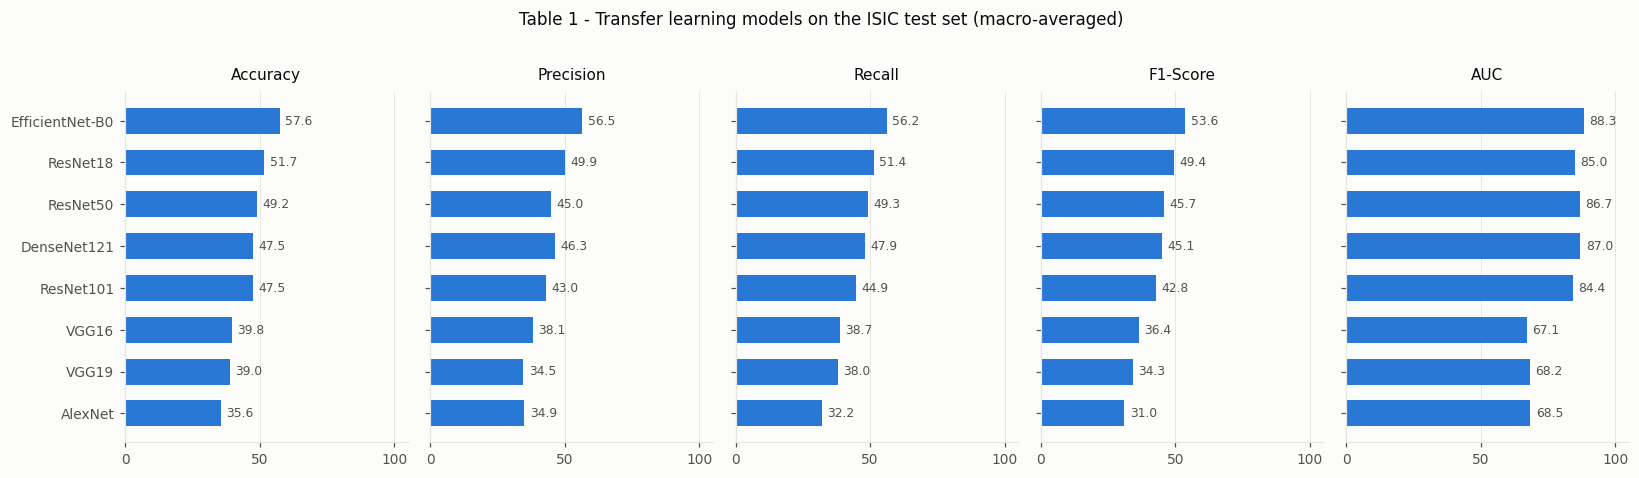

In [ ]:
import matplotlib.pyplot as plt

fig1 = plot_table1(table1, cfg.out_dir); plt.show()

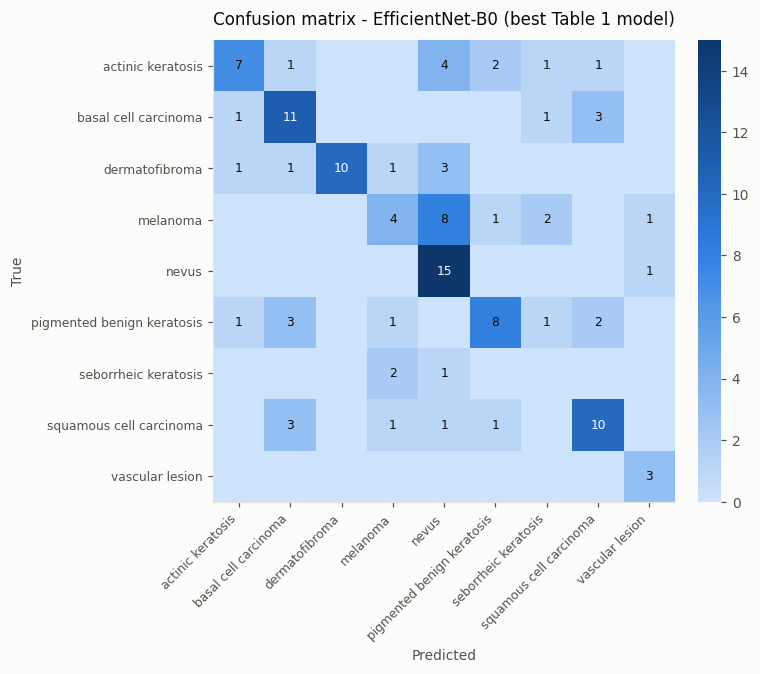

In [ ]:
best_model = table1.sort_values("Accuracy (%)", ascending=False)["Model"].iloc[0]
fig2 = plot_confusion(data.y_test.numpy(), pred_cache[best_model]["y_pred"], data.classes,
                      "Confusion matrix - %s (best Table 1 model)" % best_model,
                      cfg.out_dir); plt.show()

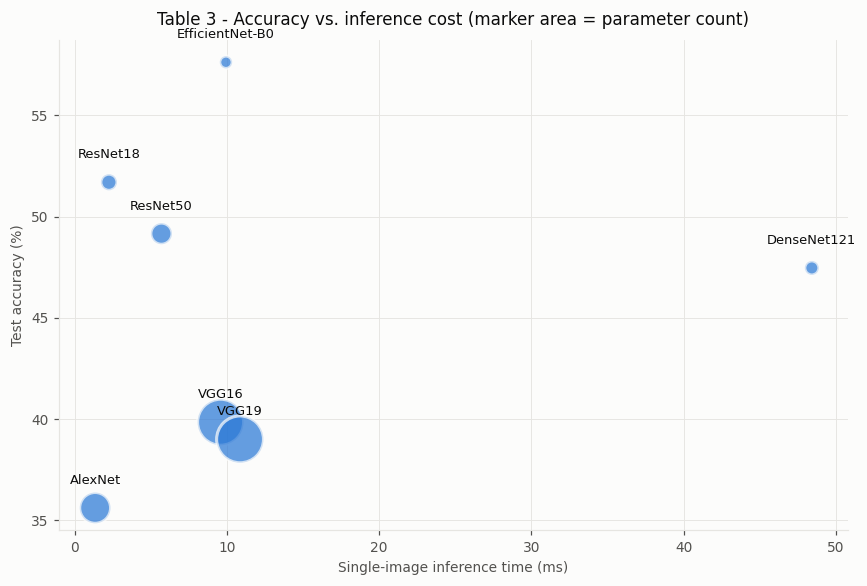

In [ ]:
fig3 = plot_efficiency(table3, cfg.out_dir); plt.show()

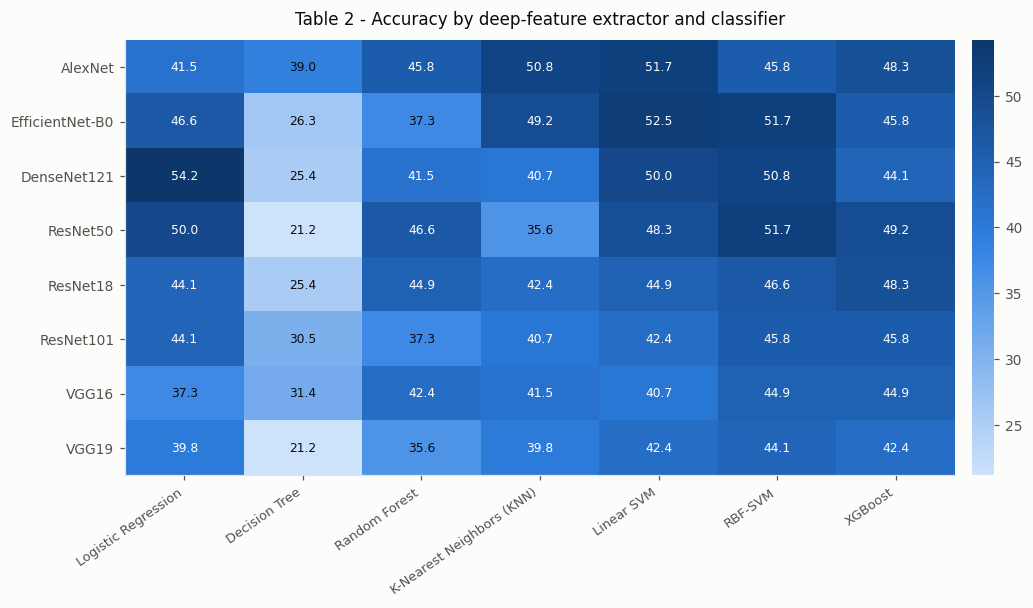

In [ ]:
fig4 = plot_table2_heatmap(table2, cfg.out_dir); plt.show()

---
## 8 · Export the filled-in tables

Writes `results/` containing the three CSVs, the plots, a `config.json` recording the exact
protocol, and **`Task 01 - Results.docx`** with all three tables filled in and laid out in
the same order as the original task document.

In [ ]:
save_results(table1, table2, table3, cfg, data, cfg.out_dir)

import os
for f in sorted(os.listdir(cfg.out_dir)):
    print(" ", f)

Wrote results/Task 01 - Results.docx
Wrote CSVs + config.json to results
  Task 01 - Results.docx
  config.json
  confusion.png
  table1_models.png
  table1_transfer_learning.csv
  table2_classifiers.csv
  table2_heatmap.png
  table3_efficiency.csv
  table3_efficiency.png


In [ ]:
# Zip everything up and download it
import shutil
from google.colab import files

shutil.make_archive("lab01_results", "zip", cfg.out_dir)
files.download("lab01_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Notes for the write-up

- **The test set is small.** The official `Test/` folder holds only ~118 images (~13 per
  class), so each image moves accuracy by ~0.85% and the ranking between closely-placed
  models is not statistically meaningful. Say so when you discuss Table 1.
- **Frozen vs fine-tuned.** These numbers are linear probes on frozen ImageNet features.
  A full fine-tune (`fine_tune=True`) typically adds a substantial margin, at the cost of
  a much longer run.
- **Class imbalance** is handled with a class-weighted loss and macro-averaged metrics, so
  the small classes (dermatofibroma, seborrheic keratosis) count as much as the large ones.
- **Subsampling.** `max_train_per_class=150` caps the training set for speed. Set it to
  `None` for the full 2239 training images before you generate final numbers.